Consider the dataset invertebrate. It holds 280 records of flying nocturnal invertebrate (e.g., insects such as moths, beetles, mosquitos, etc.) biodiversity, based on 280 sampling events in 2017 in a province in France. The outcome of interest is the Shannon-Wiener index (SWI), which is a measure of biodiversity.

Within the context of this project, it suffices to know that SWI is a non-negative metric that is usually in practice smaller than 4.5. Low values denote low diversity, while higher values denote higher diversity. In addition to SWI, a number of explanatory variables are collected as well. An overview of all variables in the data is given in the variable description table mentioned below.

The goal of this analysis is to build a model of SWI as a function of SWF, temperature, size, management, and, duration.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv("https://raw.githubusercontent.com/dphi-official/Datasets/master/Invertebrate/Invertebrate_dataset.csv")
data.head()

,SWI,SWF,temperature,size,management,duration
0,0.59,1.30,3.5,0.5,2,20
1,1.21,1.85,4.6,47.2,3,19
2,1.08,0.97,4.8,53.3,4,22
3,1.60,1.67,5.2,27.2,8,20
4,2.95,2.41,5.7,38.8,6,22


By obseravtion this is a Regression problem and will use Regression Algorithms

In [ ]:
data.describe()

,SWI,SWF,temperature,size,management,duration
count,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000
mean,1.896714,1.480679,16.372500,41.138214,4.082143,31.307143
std,0.610995,0.476403,3.619312,19.434496,2.520959,4.198304
min,0.480000,0.250000,3.500000,0.500000,0.000000,19.000000
25%,1.507500,1.190000,14.100000,27.275000,2.000000,29.000000
50%,1.825000,1.495000,17.050000,41.100000,4.000000,32.000000
75%,2.282500,1.790000,19.125000,54.725000,6.000000,34.000000
max,3.790000,2.840000,21.600000,94.200000,8.000000,41.000000


Understanding our variable names

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SWI          280 non-null    float64
 1   SWF          280 non-null    float64
 2   temperature  280 non-null    float64
 3   size         280 non-null    float64
 4   management   280 non-null    int64  
 5   duration     280 non-null    int64  
dtypes: float64(4), int64(2)
memory usage: 13.2 KB


In [ ]:
# Checking for missing data in our dataset
data.isnull().sum()

,0
SWI,0
SWF,0
temperature,0
size,0
management,0
duration,0


There are no missing values hence our data is ready now . We will now check for outliers in our dataset

<Axes: >

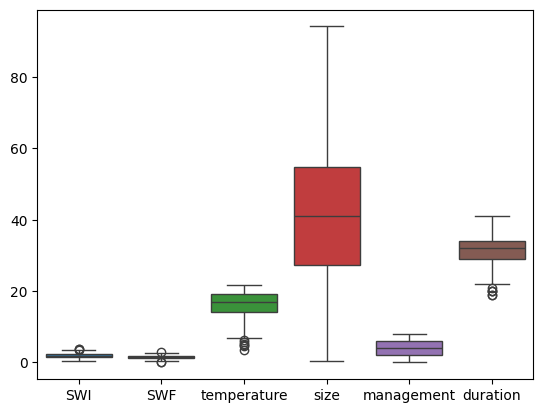

In [ ]:
sns.boxplot(data=data)

It is visible we have outliers in our data and we'll remove them. We will use this formula
Lower Bound = Q1 - 1.5 \times \text{IQR}
Upper Bound = Q3 + 1.5 \times \text{IQR}
If our data is below and above this ranges we classify them as outliers hence are subject to removal

In [ ]:
Q1 = np.percentile(data,25,axis=0)
Q3 = np.percentile(data,75,axis=0)
IQR = Q3-Q1

In [ ]:
Lower_bound = Q1 - 1.5*IQR
Upper_bound = Q3 + 1.5*IQR
print(f'Lower Bound : {Lower_bound} and our Upper Bound : {Upper_bound}')

Lower Bound : [  0.345    0.29     6.5625 -13.9     -4.      21.5   ] and our Upper Bound : [ 3.445   2.69   26.6625 95.9    12.     41.5   ]


In [ ]:
outlier_data = data[(data < Lower_bound) | (data > Upper_bound).any(axis = 1)]
outlier_data

,SWI,SWF,temperature,size,management,duration
0,NaN,NaN,3.5,NaN,NaN,20.0
1,NaN,NaN,4.6,NaN,NaN,19.0
2,NaN,NaN,4.8,NaN,NaN,NaN
3,NaN,NaN,5.2,NaN,NaN,20.0
4,NaN,NaN,5.7,NaN,NaN,NaN
...,...,...,...,...,...,...
275,NaN,NaN,NaN,NaN,NaN,NaN
276,NaN,NaN,NaN,NaN,NaN,NaN
277,NaN,NaN,NaN,NaN,NaN,NaN
278,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#Removing the ouliers
data = data.drop(outlier_data.index)

KeyError: "['SWI', 'SWF', 'temperature', 'size', 'management', 'duration'] not found in axis"

In [ ]:
data

,SWI,SWF,temperature,size,management,duration


Data Visualization

1. Heatmap

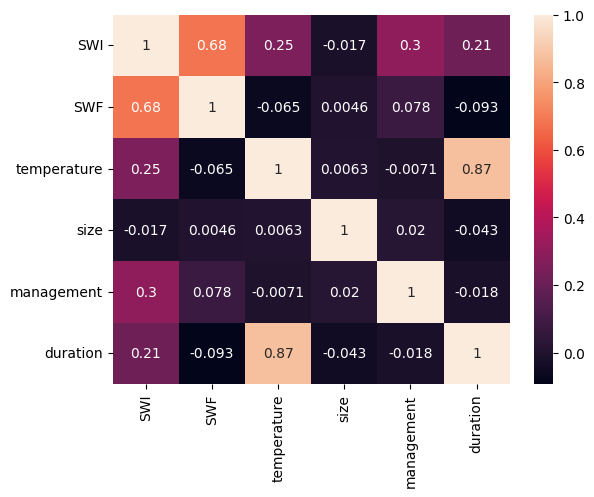

In [ ]:
sns.heatmap(data.corr(),annot=True)
plt.show()

In [ ]:
np.min(data.corr())

-0.09316517366272707

There is a strong relationship between Temperature and Duration while a weak association between duration and Shannon-Wiener index for floristic diversity on the patch

2. Regression plots

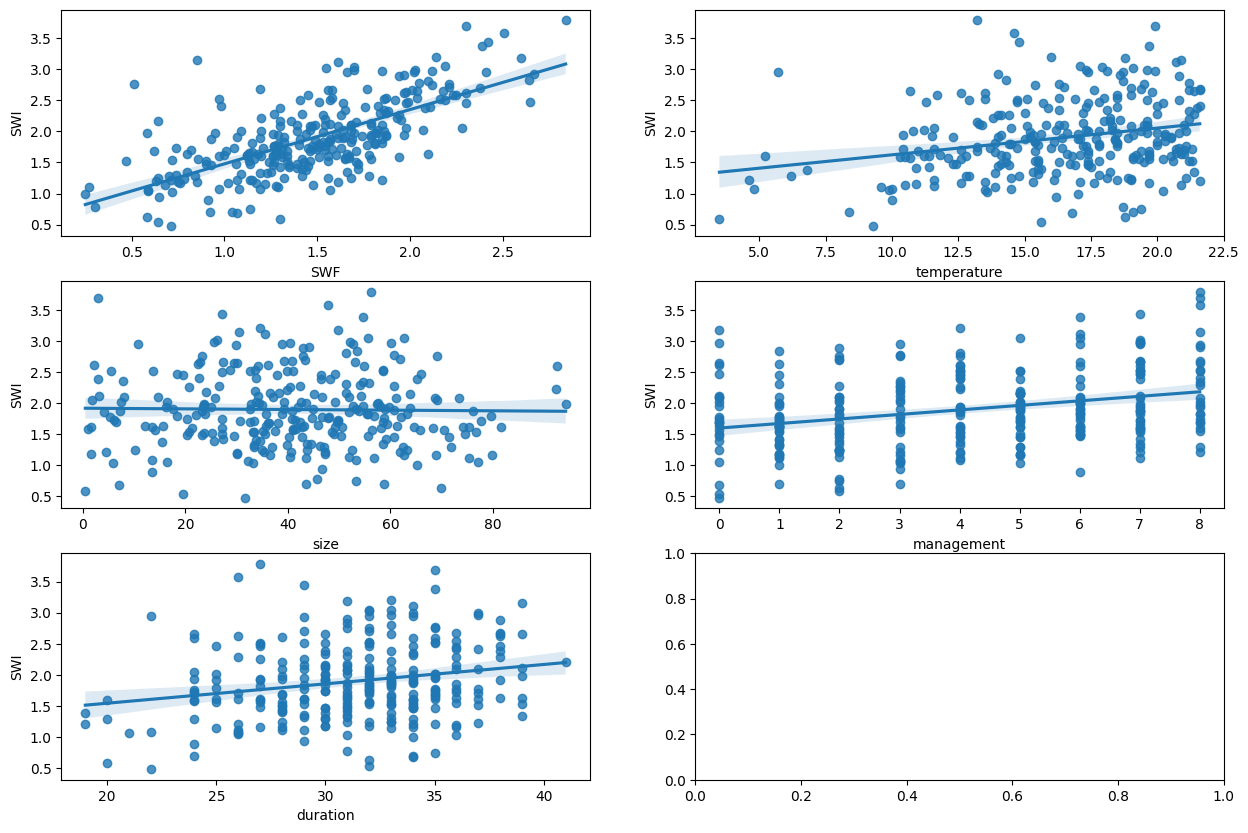

In [ ]:
fig,axs = plt.subplots(3,2,figsize=(15,10))
sns.regplot( x = data['SWF'], y = data['SWI'],ax = axs[0,0])
sns.regplot( x = data['temperature'], y = data['SWI'],ax = axs[0,1])
sns.regplot(x = data['size'],y = data['SWI'],ax = axs[1,0])
sns.regplot(x = data['management'], y = data['SWI'],ax = axs[1,1])
sns.regplot( x = data['duration'], y = data['SWI'],ax = axs[2,0])
plt.show()



3 . Distplot

<ipython-input-27-3eb0d5a3a036>:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['SWI'])


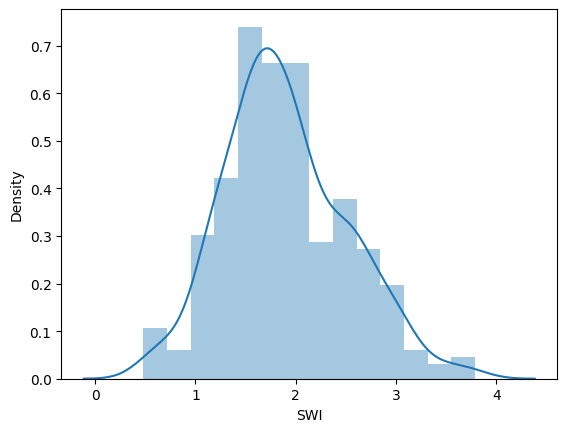

In [ ]:
sns.distplot(data['SWI'])
plt.show()

4 . Joint plot of SWI and SWI

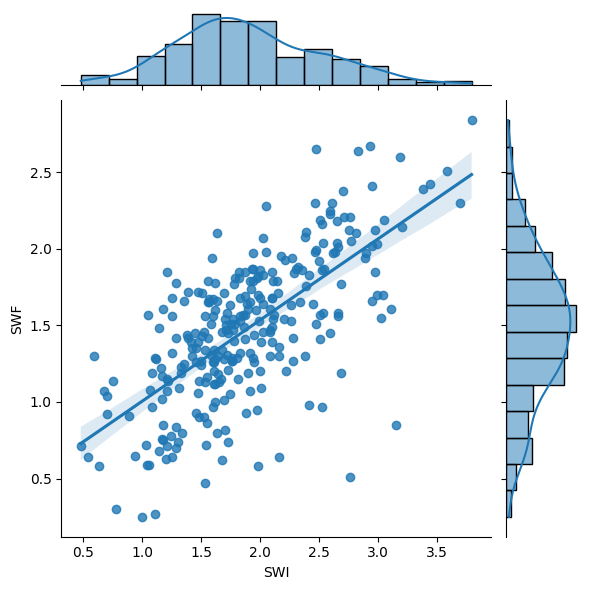

In [ ]:
sns.jointplot(x = 'SWI',y = 'SWF',data = data,kind = 'reg')
plt.show()

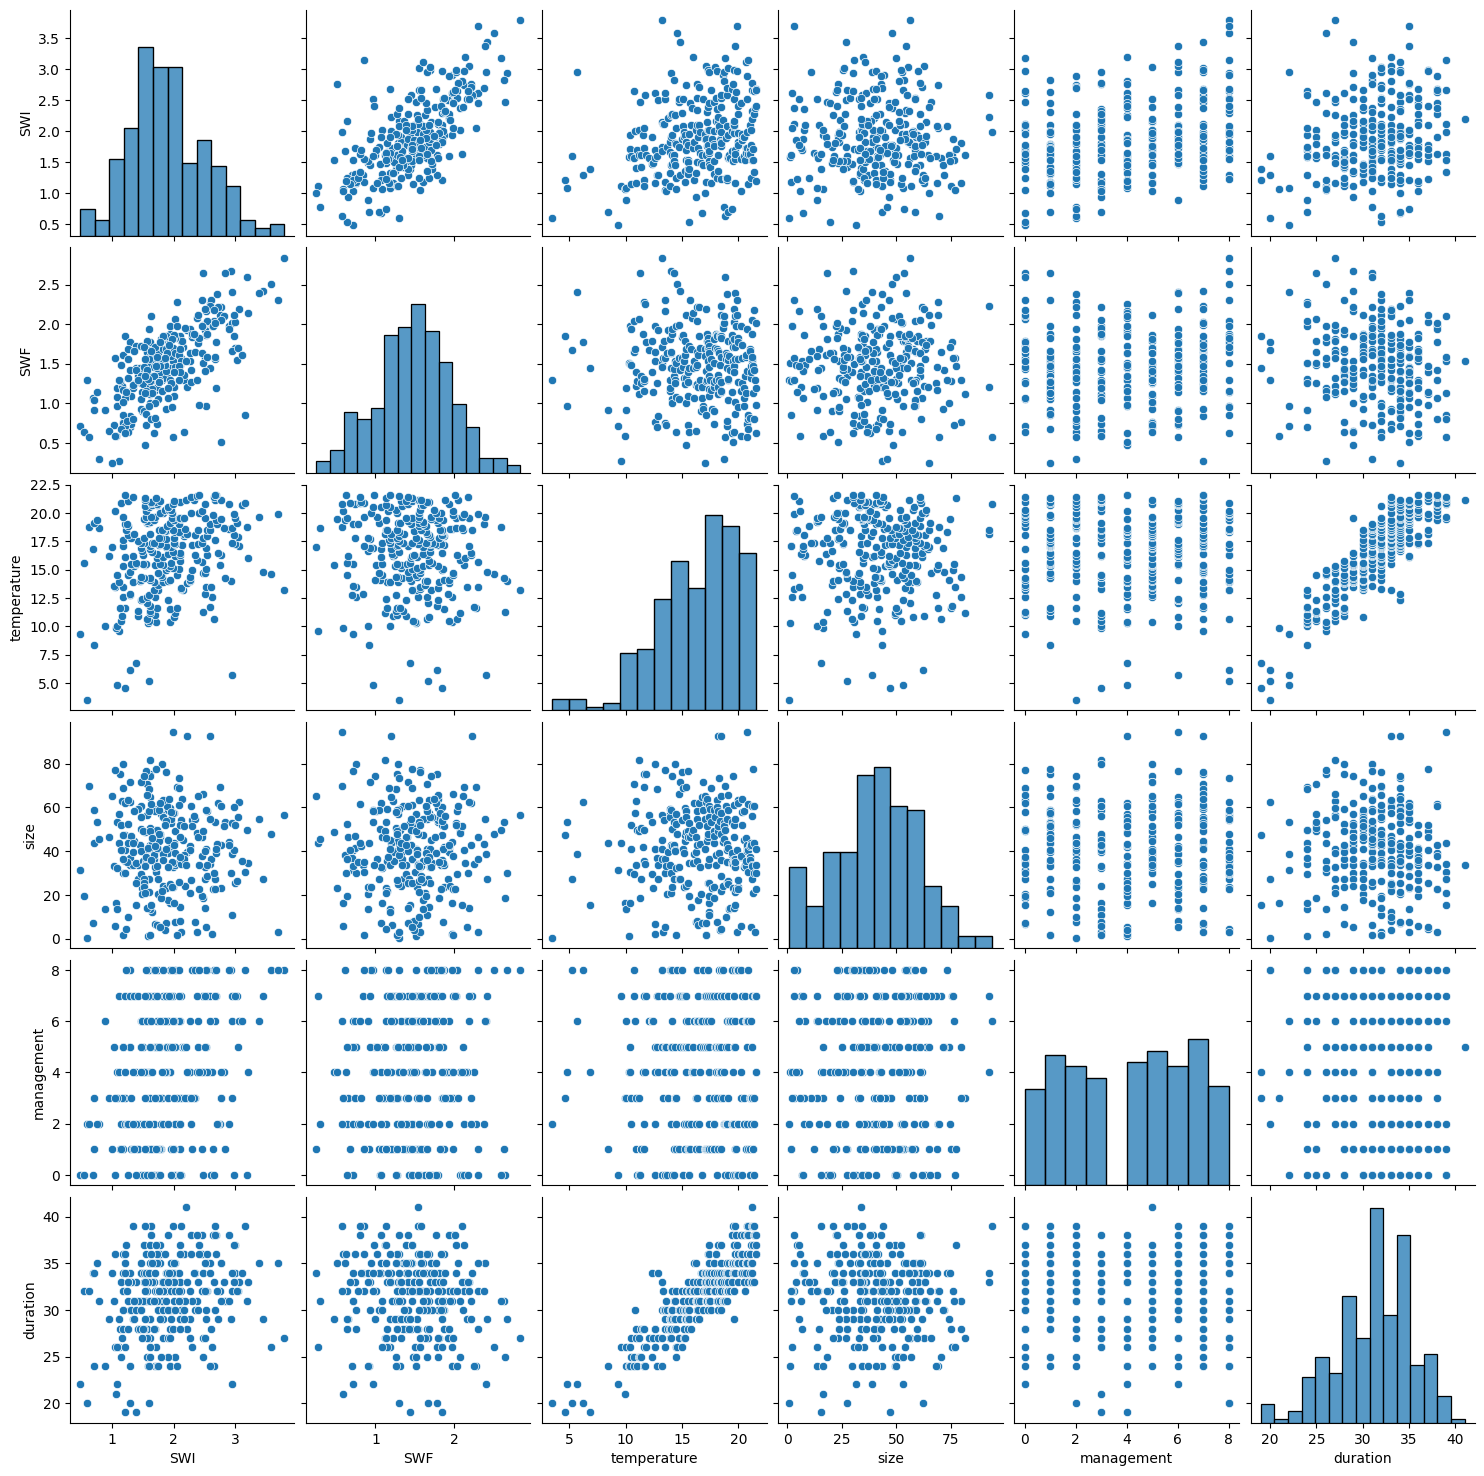

In [ ]:
sns.pairplot(data)
plt.show()

Separating Input Features and Output Features

In [4]:
X = data.drop('SWI',axis = 1)
y = data['SWI']

In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)

1. Linear Regression

In [6]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [13]:
from sklearn.metrics import r2_score,mean_squared_error
y_pred = lr.predict(X_test)
r2 = r2_score(y_test,y_pred)
error = mean_squared_error(y_test,y_pred)
print(f'R2 Score : {r2} and Error : {error}')

R2 Score : 0.4931742635218218 and Error : 0.15794260849858555


Our model had an R squared as at 49.31 % and a relatively low mean squared error of 0.15794

2. Random Forest Regressor

In [8]:
from sklearn.ensemble  import RandomForestRegressor
rf = RandomForestRegressor()
rf.fit(X_train,y_train)

RandomForestRegressor()

In [9]:
rf_pred = rf.predict(X_test)
r2 = r2_score(y_test,rf_pred)
error = mean_squared_error(y_test,rf_pred)
print(f'R2 Score : {r2} and Error : {error}')

R2 Score : 0.463100962963539 and Error : 0.1673143810714286


Our model has an R squared score of 44.74 % and a relatively higher mean squared error than Multiple Linear Regression at 0.172

3 . Support Vector Machines

In [11]:
from sklearn.svm import SVR
svm_model = SVR()
svm_model.fit(X_train,y_train)


SVR()

In [12]:
y_pred = svm_model.predict(X_test)
r2 = r2_score(y_test,y_pred)
error = mean_squared_error(y_test,y_pred)
print(f'R2 Score : {r2} and Error : {error}')

R2 Score : -0.028253236335496146 and Error : 0.320435579046277


From the three models Linear Regression performed better than all other models with an R-squared score of 49.31 % and a lower mean squared error hence a perfect model to solve our problem

Hyper-parameter Tuning

In [14]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
param_space = {
    'fit_intercept':[True,False],
    'copy_X':[True,False],
    'n_jobs':[1,2,3,4,5,6,7,8,9,10]
}

In [15]:
grid = GridSearchCV(lr,param_space,cv=10)
grid.fit(X_train,y_train)

/usr/local/lib/python3.10/dist-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


GridSearchCV(cv=10, estimator=LinearRegression(),
             param_grid={'copy_X': [True, False],
                         'fit_intercept': [True, False],
                         'n_jobs': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]})

In [17]:
grid.best_params_

{'copy_X': True, 'fit_intercept': True, 'n_jobs': 1}

In [18]:
lr = LinearRegression(copy_X=True,fit_intercept=True,n_jobs=1)
lr.fit(X_train,y_train)

LinearRegression(n_jobs=1)

In [19]:
y_pred = lr.predict(X_test)
r2 = r2_score(y_test,y_pred)
error = mean_squared_error(y_test,y_pred)
print(f'R2 Score : {r2} and Error : {error}')

R2 Score : 0.4931742635218218 and Error : 0.15794260849858555


2. Randomized Search CV

In [20]:
random_cv = RandomizedSearchCV(lr,param_space,cv=10)
random_cv.fit(X_train,y_train)
random_cv.best_params_

{'n_jobs': 3, 'fit_intercept': True, 'copy_X': False}

In [22]:
lr = LinearRegression(copy_X= False,fit_intercept=True,n_jobs=3)
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2 = r2_score(y_test,y_pred)
error = mean_squared_error(y_test,y_pred)
print(f'R2 Score : {r2} and Error : {error}')

R2 Score : 0.4931742635218218 and Error : 0.15794260849858555


Nothing changed from our data but since the R squared score is too low we may have to try out Hyperparameter tuning on the Random Forest Regressor and SVM to see if the results will improve

Random Forest Regressor Hyperparamter Tuning

In [23]:
param_grid_1 = {
    'n_estimators':(2,100),
    'max_features':('auto','sqrt'),
    'max_depth':(2,50),
    'min_samples_split':(2,5),
    'min_samples_leaf':(1,2)
}


In [25]:
grid_1 = GridSearchCV(rf,param_grid_1,cv=10)
grid_1.fit(X_train,y_train)
grid_1.best_params_

/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:540: FitFailedWarning: 
160 fits failed out of a total of 320.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
160 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 1466, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 666, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.10/dist-packages/sklearn/util

{'max_depth': 50,
 'max_features': 'sqrt',
 'min_samples_leaf': 2,
 'min_samples_split': 2,
 'n_estimators': 100}

In [26]:
rf = RandomForestRegressor(max_depth= 50,max_features= 'sqrt',min_samples_leaf= 2,min_samples_split= 2,n_estimators= 100)
rf.fit(X_train,y_train)

RandomForestRegressor(max_depth=50, max_features='sqrt', min_samples_leaf=2)

In [27]:
y_pred = rf.predict(X_test)
r2 = r2_score(y_test,y_pred)
error = mean_squared_error(y_test,y_pred)
print(f'R2 Score : {r2} and Error : {error}')

R2 Score : 0.5218733519052969 and Error : 0.14899908303297876


Model performance improved significantly and better than other models let's see what happens with the SVR model

Support Vector Regressor

In [28]:
param_grid_2 = {
    'kernel':('linear','poly','rbf','sigmoid'),
    'C':[1,5,10],
    'gamma':('scale','auto'),
    'epsilon':[0.1,1,10,100],
    'shrinking':[True,False]
}

In [ ]:
grid_2 = GridSearchCV(svm_model,param_grid_2,cv=10)
grid_2.fit(X_train,y_train)
grid_2.best_params_